In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
import joblib
import os
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
np.random.seed(42)


In [2]:
# Загрузка всех 4 CSV-файлов
forward_ac_df = pd.read_csv("forward_AC.csv")
forward_cb_df = pd.read_csv("forward_CB.csv")
backward_ca_df = pd.read_csv("backward_CA.csv")
backward_bc_df = pd.read_csv("backward_BC.csv")

# Словарь для итерации
pathway_dfs = {
    "forward_AC": forward_ac_df,
    "forward_CB": forward_cb_df,
    "backward_CA": backward_ca_df,
    "backward_BC": backward_bc_df
}


In [3]:
def split_the_data_reg(dataset):
    X = dataset[['Time', 'Mechanism']]  # Признаки
    y = dataset['Pressure']             # Целевая переменная
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    return X_train_scaled, X_test_scaled, y_train, y_test, scaler


In [4]:
def train_reg_model(X_train, X_test, y_train, y_test, scaler, name="model"):
    model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)

    # Cross-validation (5-fold R² score)
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='r2')
    print(f"[{name}] Cross-validated R²: {scores.mean():.4f} ± {scores.std():.4f}")
    
    # Финальное обучение
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    print(f"[{name}] Test MSE: {mse:.4f}, Test R²: {r2:.4f}")
    
    os.makedirs("regressor", exist_ok=True)
    joblib.dump(model, f"regressor/{name}_gbr.pkl")
    joblib.dump(scaler, f"regressor/{name}_scaler.pkl")
    
    return y_test, y_pred


In [5]:
def plot_reg(y_test, y_pred, name=""):
    plt.figure(figsize=(10, 5))
    sns.scatterplot(x=y_test, y=y_pred)
    plt.xlabel("Actual Pressure")
    plt.ylabel("Predicted Pressure")
    plt.title(f"{name}: Actual vs Predicted Pressure")
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
    plt.tight_layout()
    plt.show()



--- Processing forward_AC ---
[forward_AC] Cross-validated R²: 0.7593 ± 0.0338
[forward_AC] Test MSE: 0.1855, Test R²: 0.8038


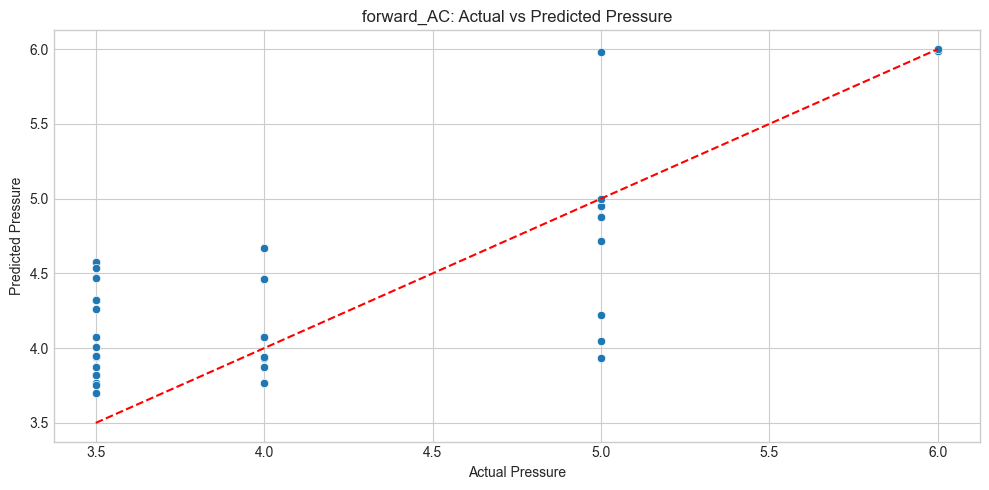


--- Processing forward_CB ---
[forward_CB] Cross-validated R²: 0.8027 ± 0.0189
[forward_CB] Test MSE: 0.2167, Test R²: 0.7708


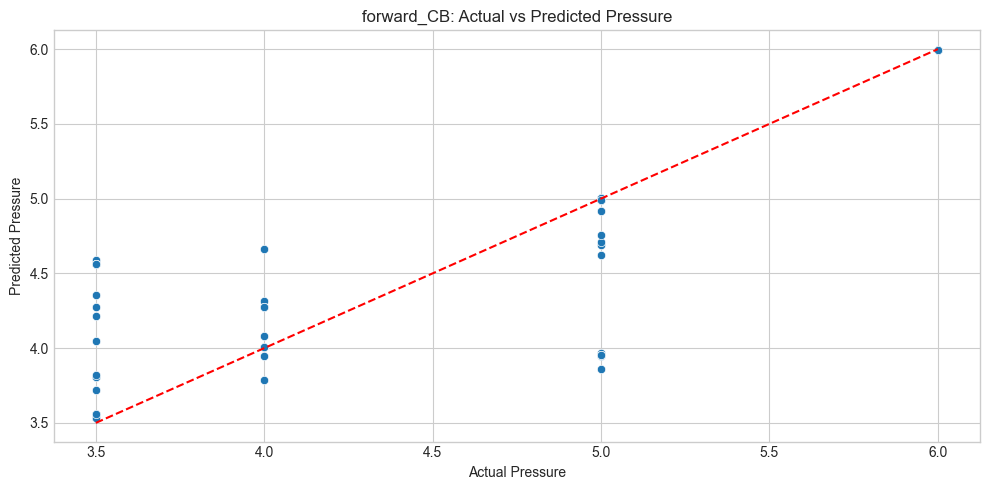


--- Processing backward_CA ---
[backward_CA] Cross-validated R²: 0.6429 ± 0.0384
[backward_CA] Test MSE: 0.2535, Test R²: 0.7391


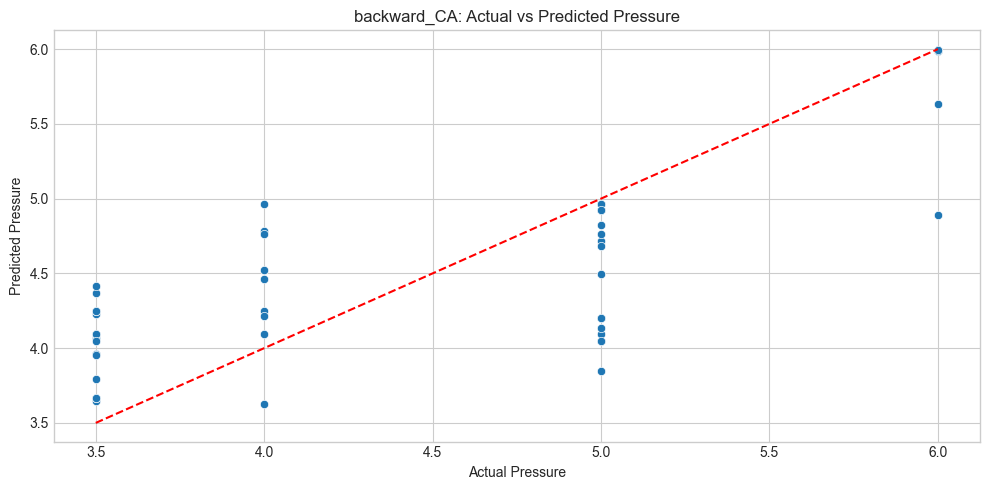


--- Processing backward_BC ---
[backward_BC] Cross-validated R²: 0.8810 ± 0.0234
[backward_BC] Test MSE: 0.0872, Test R²: 0.9102


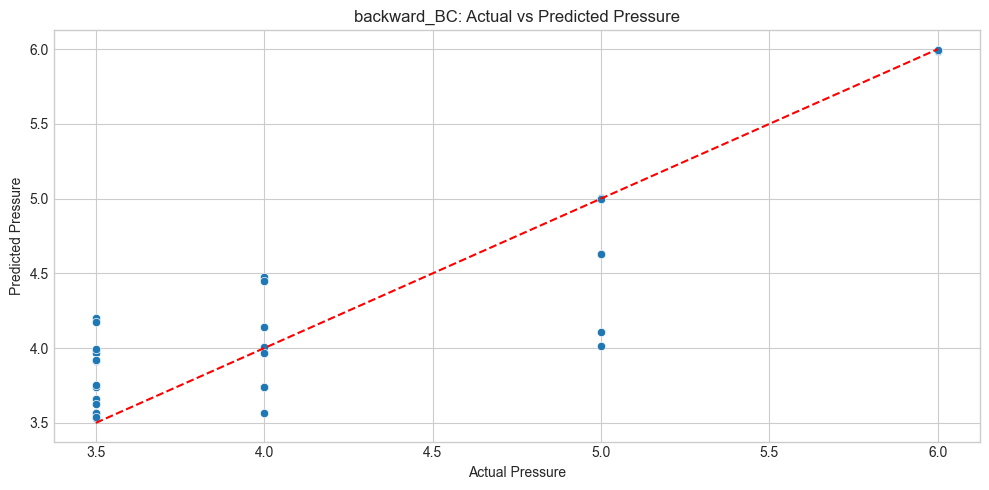

In [6]:
for name, df in pathway_dfs.items():
    print(f"\n--- Processing {name} ---")
    X_train, X_test, y_train, y_test, scaler = split_the_data_reg(df)
    y_test, y_pred = train_reg_model(X_train, X_test, y_train, y_test, scaler, name)
    plot_reg(y_test, y_pred, name)
